# Issue #11 · fixed-class bootstrap review (analysis v2)

This executed analysis corrects the recovery estimand using the **original saved
YOLO26n predictions**. No detector, corruption generator, source-image preparation,
model training, development validation or final-test evaluation is run here.

The original [executed v1 study](evidence/02b_synthetic_robustness_v1.ipynb) retains
its complete design, negative findings, images and original results. Its variable-class
bootstrap intervals are superseded by this notebook. Original six-class native AP
point estimates remain descriptive and unchanged. **Five-class supported recovery
and its interval are a different, explicitly named estimand**, not a corrected
six-class confidence interval. No v3 router is enabled.

In [1]:
import gzip
import importlib.metadata as metadata
from pathlib import Path
from unittest.mock import patch

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from vehicle_detection.common import digest, file_hash, read_json, write_json
from vehicle_detection.data import CLASSES
from vehicle_detection.protocol import validate_protocol
from vehicle_detection.robustness_spec import final_stress_spec
from vehicle_detection.stress import freeze, validate_pilot
from vehicle_detection.stress_eval import (
    bootstrap_support,
    class_ap,
    load_recorded_calibration,
    paired_interval,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
SOURCE = ROOT / "runs/issue11-v1"
RUN_ROOT, REPORT = ROOT / "runs/issue11-v2", ROOT / "docs/issue11-v2"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
REPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
protocol = validate_protocol(read_json(ROOT / "runs/issue5-v1/protocol.json"))
pilot = validate_pilot(read_json(SOURCE / "pilot.json"), protocol)
source_study = read_json(ROOT / "docs/issue11-v1/study.json")
source_summary = read_json(ROOT / "docs/issue11-v1/summary.json")
source_matrix_path = ROOT / "docs/issue11-v1/experimental_matrix.csv"
if file_hash(source_matrix_path) != source_summary["matrix_sha256"]:
    raise ValueError("Original measured matrix changed")
if (
    source_study["study_id"] != source_summary["study_id"]
    or pilot["pilot_id"] != source_study["pilot_id"]
):
    raise ValueError("Source study/pilot identities differ")
source_matrix = pd.read_csv(source_matrix_path, float_precision="round_trip")
results, stats = {}, {}
# A regression guard for the full executed reanalysis: native inference is forbidden.
inference_guard = patch(
    "vehicle_detection.stress_eval.YOLO", side_effect=RuntimeError("No inference in reanalysis")
)
inference_guard.start()
for name, expected in source_summary["experiment_identities"].items():
    results[name], stats[name] = load_recorded_calibration(
        SOURCE / "evaluation" / name,
        expected,
        pilot=pilot,
        protocol_id=protocol["manifest_id"],
        checkpoint=source_study["checkpoint"],
        settings=source_study["settings"],
        code=source_study["code"]["stress_eval.py"],
    )
clean = "clean-s0-skip"
SEED, RESAMPLES, MIN_GROUPS = 2026, 100, 5
policy = bootstrap_support(stats[clean], pilot, min_class_groups=MIN_GROUPS)
target = policy["class_ids"]
analysis = {
    "version": "issue11-analysis-v2",
    "source_study_id": source_study["study_id"],
    "source_summary_sha256": file_hash(ROOT / "docs/issue11-v1/summary.json"),
    "source_matrix_sha256": file_hash(source_matrix_path),
    "pilot_id": pilot["pilot_id"],
    "role": "calibration",
    "seed": SEED,
    "bootstrap_draws": RESAMPLES,
    "estimand": policy,
    "gates": source_study["gates"],
    "gate_metric": "fixed supported-class recovery and clean loss, not six-class native recovery",
    "code": {
        name: file_hash(ROOT / "src/vehicle_detection" / name)
        for name in ["stress_eval.py", "robustness_spec.py"]
    },
    "versions": {p: metadata.version(p) for p in ["numpy", "ultralytics", "pandas", "matplotlib"]},
    "prediction_statistics_sha256": {
        name: v["statistics_sha256"] for name, v in source_summary["experiment_identities"].items()
    },
    "inference_run": False,
}
analysis["analysis_id"] = digest(analysis)
freeze(RUN_ROOT / "analysis.json", analysis)
freeze(REPORT / "analysis.json", analysis)
print("Verified original experiments:", len(results))
print("Fixed supported classes:", policy["class_names"])
print("Source checkpoint:", source_study["checkpoint"])
display(pd.DataFrame(policy["support"]))

Verified original experiments: 45
Fixed supported classes: ['car', 'truck', 'bus', 'motorcycle', 'bicycle']
Source checkpoint: 9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef


,class_id,class,images,instances,source_groups,included,reason
0,0,car,254,2621,156,True,None
1,1,truck,75,122,64,True,None
2,2,bus,40,48,35,True,None
3,3,train,1,1,1,False,insufficient source groups
4,4,motorcycle,10,16,10,True,None
5,5,bicycle,12,22,12,True,None


## Fixed support policy and statistical population

Select the target once from original ground truth: a class needs **at least five
source groups**. This is an engineering minimum, not statistical adequacy. The
pilot supports car/truck/bus/motorcycle/bicycle; train occurs in one image/group and
receives descriptive AP only, with **no class CI**.

Draw 158 source groups with replacement, paired identically pre/post. Every macro
estimate averages the **same five classes**. A draw missing any required class is
marked invalid, excluded without imputation and not replaced. The percentile interval
is conditional on target-class presence; all invalid counts are reported. Per-class
intervals use draws containing that eligible class and report their own denominators.
Every draw records images, instances and distinct original source groups for all six
classes, including excluded train. Repeated source groups do not add independent support.

The old analysis omitted train in 43/100 draws and thereby changed its denominator.
Those omissions may still occur, but cannot change this fixed five-class target.
Point recovery, clean safety and the shortlist gate all use this same target. Nominal
95% intervals remain exploratory, with 100 draws and no multiplicity correction.

No images, GT boxes, predictions or split memberships are removed. Only the
statistical macro target excludes the unsupported class.

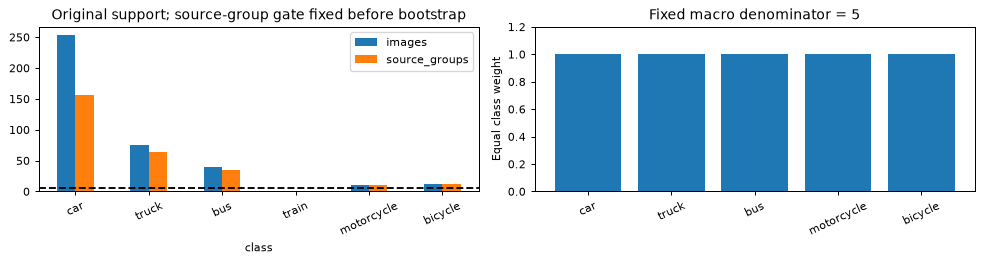

All original native AP point estimates reproduced without inference


In [2]:
support_table = pd.DataFrame(policy["support"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
support_table.set_index("class")[["images", "source_groups"]].plot.bar(ax=axes[0], rot=25)
axes[0].axhline(MIN_GROUPS, linestyle="--", color="black")
axes[0].set_title("Original support; source-group gate fixed before bootstrap")
axes[1].bar(policy["class_names"], [1] * len(target))
axes[1].set(title="Fixed macro denominator = 5", ylabel="Equal class weight", ylim=(0, 1.2))
axes[1].tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(REPORT / "fixed_class_support.png")
plt.show()
aps = {name: class_ap(values, list(values)) for name, values in stats.items()}
points = {name: float(np.mean([values[c] for c in target])) for name, values in aps.items()}
for name in results:
    if abs(np.mean(list(aps[name].values())) - results[name]["overall"]["mAP50_95"]) > 1e-8:
        raise ValueError("Reaggregation differs from recorded native AP")
print("All original native AP point estimates reproduced without inference")

In [3]:
old_ci_columns = ["recovery_ci_low", "recovery_ci_high", "resamples", "groups", "interval"]
matrix = source_matrix.drop(columns=old_ci_columns).rename(
    columns={
        "mAP50_95": "native_mAP50_95",
        "recovery": "native_recovery",
        "degradation": "native_degradation",
    }
)
intervals, ledgers, class_rows = {}, [], []
for i, row in matrix.iterrows():
    name = row.experiment
    raw_name = f"{row.family}-s{int(row.severity)}-skip"
    clean_name = f"clean-s0-{row.operator}"
    matrix.loc[i, "supported_mAP50_95"] = points[name]
    matrix.loc[i, "supported_recovery"] = points[name] - points[raw_name]
    matrix.loc[i, "supported_clean_loss"] = points[clean] - points[clean_name]
    if row.operator == "skip":
        continue
    interval = paired_interval(
        stats[raw_name],
        stats[name],
        pilot,
        resamples=RESAMPLES,
        seed=SEED,
        min_class_groups=MIN_GROUPS,
    )
    if interval["estimand"] != policy:
        raise ValueError("Target support changed between comparisons")
    if abs(interval["recovery"] - matrix.loc[i, "supported_recovery"]) > 1e-12:
        raise ValueError("Point and interval estimands differ")
    freeze(RUN_ROOT / "intervals" / f"{name}.json", interval)
    intervals[name] = interval
    for field in ["recovery_ci_low", "recovery_ci_high", "valid_draws", "invalid_draws"]:
        matrix.loc[i, "supported_" + field] = interval[field]
    class_rows.extend({"experiment": name, **record} for record in interval["per_class"])
    for draw in interval["draws"]:
        observed = sum(c["images"] > 0 for c in draw["class_support"])
        for cls in draw["class_support"]:
            ledgers.append(
                {
                    "experiment": name,
                    "draw": draw["draw"],
                    "valid_macro": draw["valid"],
                    "fixed_denominator": len(target),
                    "observed_classes": observed,
                    "missing_required_ids": ",".join(map(str, draw["missing_class_ids"])),
                    "macro_recovery": draw["recovery"],
                    "class": CLASSES[cls["class_id"]],
                    "included": cls["class_id"] in target,
                    **cls,
                }
            )
matrix.to_csv(REPORT / "experimental_matrix.csv", index=False)
per_class = pd.DataFrame(class_rows)
per_class.to_csv(REPORT / "per_class_recovery.csv", index=False)
ledger = pd.DataFrame(ledgers)
(REPORT / "bootstrap_draw_support.csv.gz").write_bytes(
    gzip.compress(ledger.to_csv(index=False).encode(), mtime=0)
)
first = next(iter(intervals.values()))
print("Macro draws:", first["valid_draws"], "valid;", first["invalid_draws"], "invalid")
print("Train absent draws:", sum(d["class_support"][3]["images"] == 0 for d in first["draws"]))
display(
    matrix[
        [
            "family",
            "severity",
            "operator",
            "native_mAP50_95",
            "native_recovery",
            "supported_mAP50_95",
            "supported_recovery",
            "supported_recovery_ci_low",
            "supported_recovery_ci_high",
            "supported_valid_draws",
            "supported_invalid_draws",
        ]
    ]
)
display(per_class[per_class.experiment == "veil-s2-clahe"])

Macro draws: 100 valid; 0 invalid
Train absent draws: 43


,family,severity,operator,native_mAP50_95,native_recovery,supported_mAP50_95,supported_recovery,supported_recovery_ci_low,supported_recovery_ci_high,supported_valid_draws,supported_invalid_draws
0,clean,0,skip,0.157082,0.000000,0.188499,0.000000,NaN,NaN,NaN,NaN
1,shot_read,1,skip,0.153004,0.000000,0.183604,0.000000,NaN,NaN,NaN,NaN
2,shot_read,2,skip,0.133831,0.000000,0.160597,0.000000,NaN,NaN,NaN,NaN
3,shot_read,3,skip,0.095015,0.000000,0.114018,0.000000,NaN,NaN,NaN,NaN
4,motion,1,skip,0.160593,0.000000,0.192712,0.000000,NaN,NaN,NaN,NaN
5,motion,2,skip,0.095447,0.000000,0.114537,0.000000,NaN,NaN,NaN,NaN
6,motion,3,skip,0.043638,0.000000,0.052365,0.000000,NaN,NaN,NaN,NaN
7,defocus,1,skip,0.160906,0.000000,0.193087,0.000000,NaN,NaN,NaN,NaN
8,defocus,2,skip,0.166604,0.000000,0.199925,0.000000,NaN,NaN,NaN,NaN
9,defocus,3,skip,0.147767,0.000000,0.177320,0.000000,NaN,NaN,NaN,NaN


,experiment,class_id,class,images,instances,source_groups,included,reason,before_ap,after_ap,recovery,ci_low,ci_high,valid_draws,excluded_draws,present_draws
60,veil-s2-clahe,0,car,254,2621,156,True,None,0.256322,0.269056,0.012734,0.009686,0.015928,100,0,100
61,veil-s2-clahe,1,truck,75,122,64,True,None,0.176400,0.187154,0.010755,0.000396,0.027751,100,0,100
62,veil-s2-clahe,2,bus,40,48,35,True,None,0.161902,0.186736,0.024833,-0.003864,0.057830,100,0,100
63,veil-s2-clahe,3,train,1,1,1,False,insufficient source groups,0.000000,0.000000,0.000000,NaN,NaN,0,100,57
64,veil-s2-clahe,4,motorcycle,10,16,10,True,None,0.169156,0.171744,0.002588,-0.038841,0.062763,100,0,100
65,veil-s2-clahe,5,bicycle,12,22,12,True,None,0.122217,0.143086,0.020869,-0.006790,0.051987,100,0,100


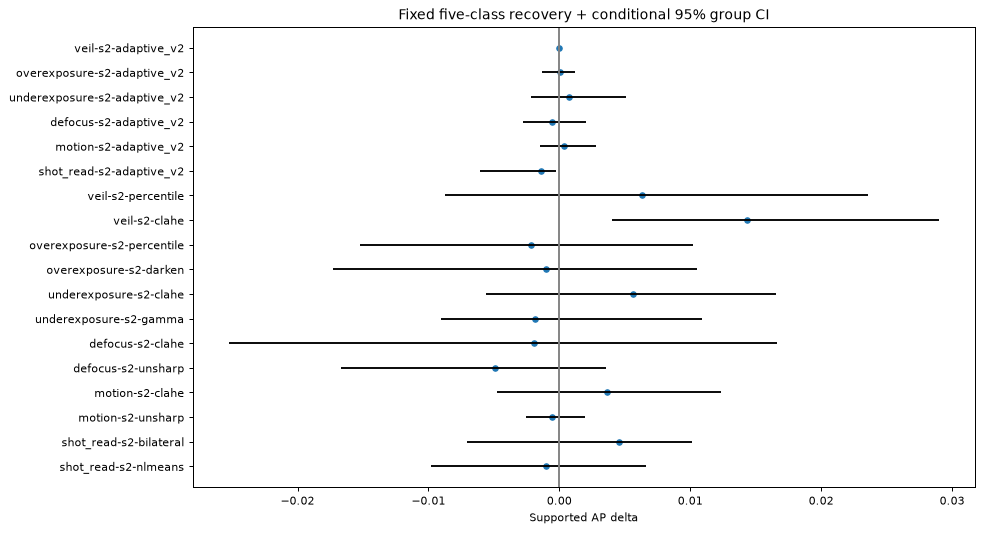

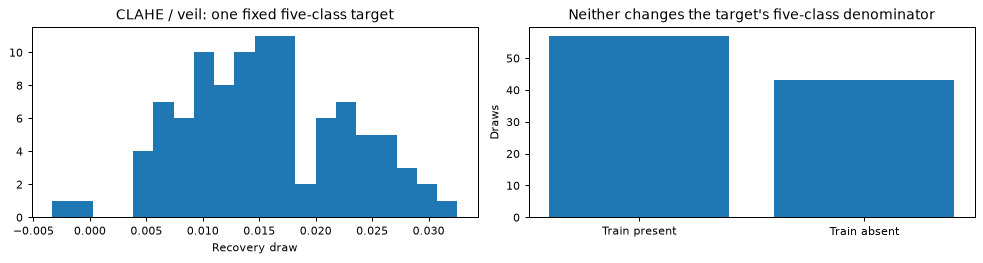

,family,operator,supported_recovery,supported_recovery_ci_low,supported_recovery_ci_high,supported_clean_loss,restore_p95_ms,passes_exploratory_gates
19,shot_read,nlmeans,-0.000995,-0.009818,0.006625,-0.011041,777.216087,False
20,shot_read,bilateral,0.004550,-0.007059,0.010141,-0.005760,6.864732,False
21,motion,unsharp,-0.000598,-0.002551,0.001951,-0.001692,2.678012,False
22,motion,clahe,0.003604,-0.004780,0.012351,-0.004608,8.748091,False
23,defocus,unsharp,-0.004898,-0.016651,0.003556,-0.001692,2.237546,False
24,defocus,clahe,-0.001963,-0.025265,0.016587,-0.004608,8.794869,False
25,underexposure,gamma,-0.001869,-0.009034,0.010892,0.003076,0.760132,False
26,underexposure,clahe,0.005624,-0.005632,0.016556,-0.004608,10.049760,False
27,overexposure,darken,-0.001038,-0.017298,0.010524,0.000050,0.855119,False
28,overexposure,percentile,-0.002165,-0.015237,0.010174,-0.000114,10.989791,False


In [4]:
screen = matrix[(matrix.family != "clean") & (matrix.operator != "skip")].copy()
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(screen))
ax.hlines(y, screen.supported_recovery_ci_low, screen.supported_recovery_ci_high, color="black")
ax.scatter(screen.supported_recovery, y, s=18)
ax.set_yticks(y, screen.experiment)
ax.axvline(0, color="gray")
ax.set(title="Fixed five-class recovery + conditional 95% group CI", xlabel="Supported AP delta")
fig.tight_layout()
fig.savefig(REPORT / "supported_recovery.png")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
veil = intervals["veil-s2-clahe"]
axes[0].hist([d["recovery"] for d in veil["draws"] if d["valid"]], bins=20)
axes[0].set(title="CLAHE / veil: one fixed five-class target", xlabel="Recovery draw")
axes[1].bar(
    ["Train present", "Train absent"],
    [
        sum(d["class_support"][3]["images"] > 0 for d in veil["draws"]),
        sum(d["class_support"][3]["images"] == 0 for d in veil["draws"]),
    ],
)
axes[1].set(title="Neither changes the target's five-class denominator", ylabel="Draws")
fig.tight_layout()
fig.savefig(REPORT / "bootstrap_audit.png")
plt.show()
gates = source_study["gates"]
shortlist = screen[screen.operator != "adaptive_v2"].copy()
shortlist["passes_exploratory_gates"] = (
    (shortlist.supported_recovery >= gates["recovery_min"])
    & (shortlist.supported_recovery_ci_low > gates["recovery_ci_low_min"])
    & (shortlist.supported_clean_loss <= gates["max_clean_loss"])
    & (shortlist.restore_p95_ms <= gates["max_restore_p95_ms"])
)
shortlist.to_csv(REPORT / "shortlist.csv", index=False)
display(
    shortlist[
        [
            "family",
            "operator",
            "supported_recovery",
            "supported_recovery_ci_low",
            "supported_recovery_ci_high",
            "supported_clean_loss",
            "restore_p95_ms",
            "passes_exploratory_gates",
        ]
    ]
)

## Operator screen remains separate from router confirmation

CLAHE under moderate **synthetic uniform veil** is only an exploratory operator
shortlist. A nominal selected-pilot CI is not independent or multiplicity-adjusted
confirmation, a natural-fog claim, or a v3 route. The pilot has one foggy image.
The high-pass indicator has cross-condition false positives; v2 is **Gamma-or-Skip**.

A later confirmation must freeze a pixel-only route and parameters before viewing
new outcomes, use whole **group-disjoint calibration** groups, and test clean safety,
negative cases, estimator precision/recall, paired fixed-target AP recovery and CPU
p50/p95. No development/final-test data may tune that route. Confirmation remains
unexecuted; the no-v3 decision is preserved.

Recorded severity and real-prediction examples below come from the original frozen
study. Green boxes are GT, orange boxes are original YOLO predictions at display
confidence 0.25; metric confidence was 0.001. No predictions are regenerated here.

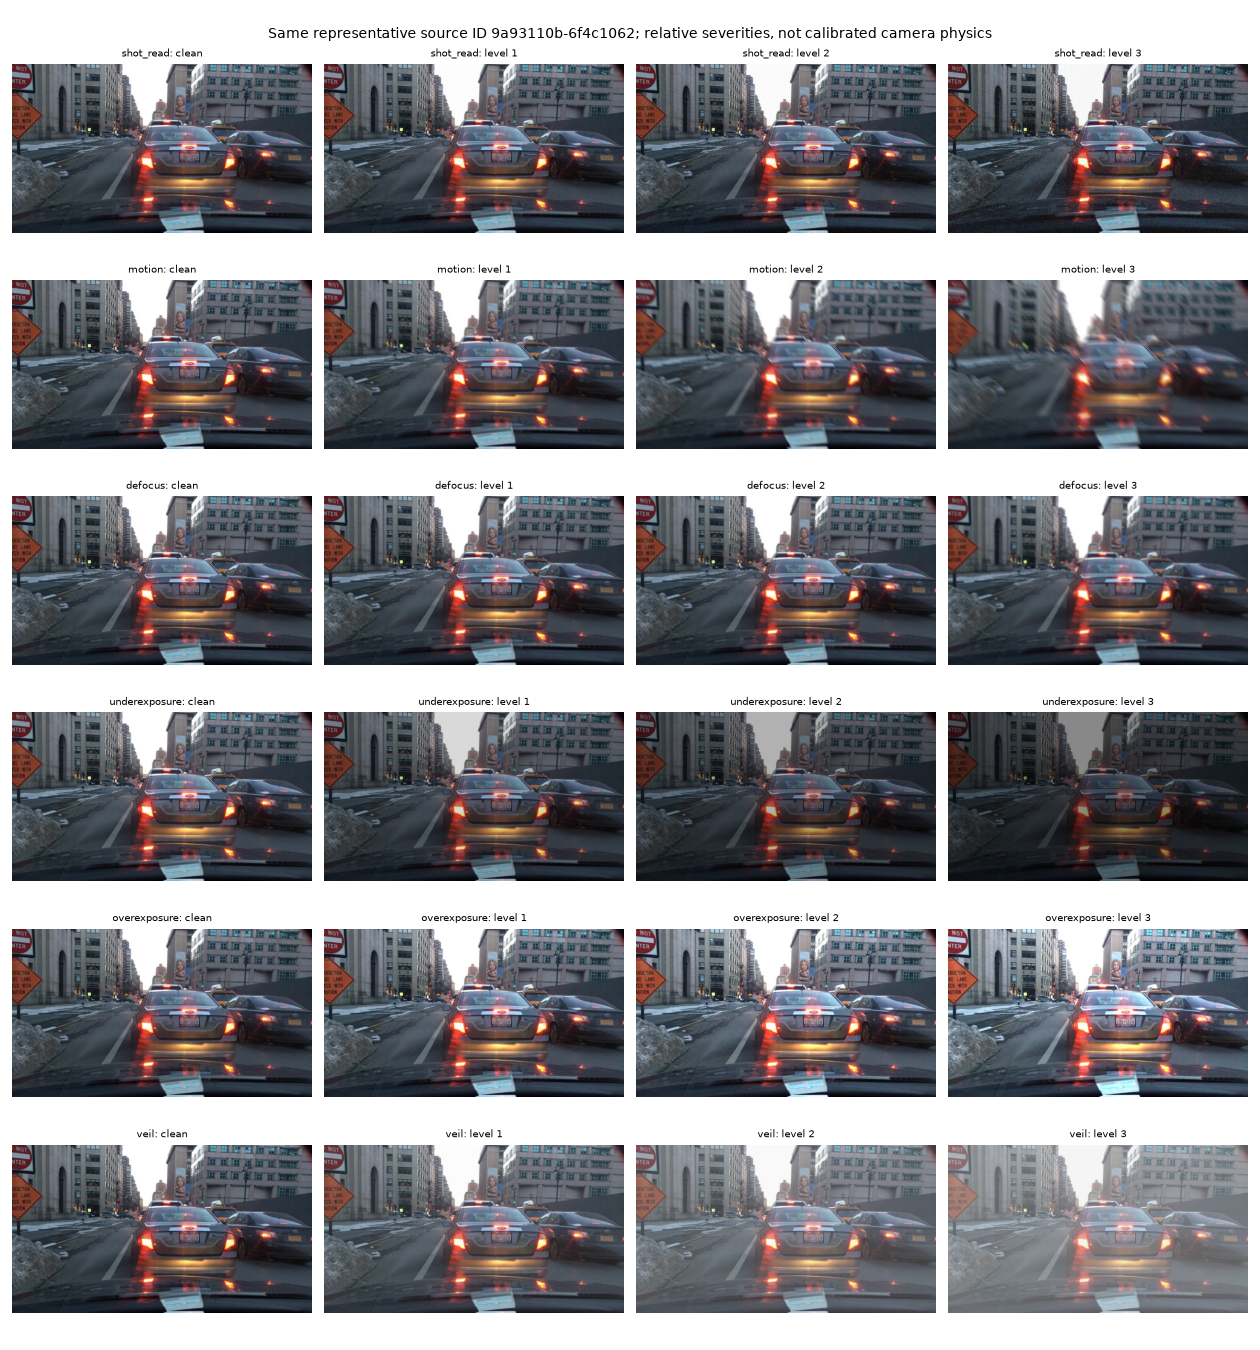

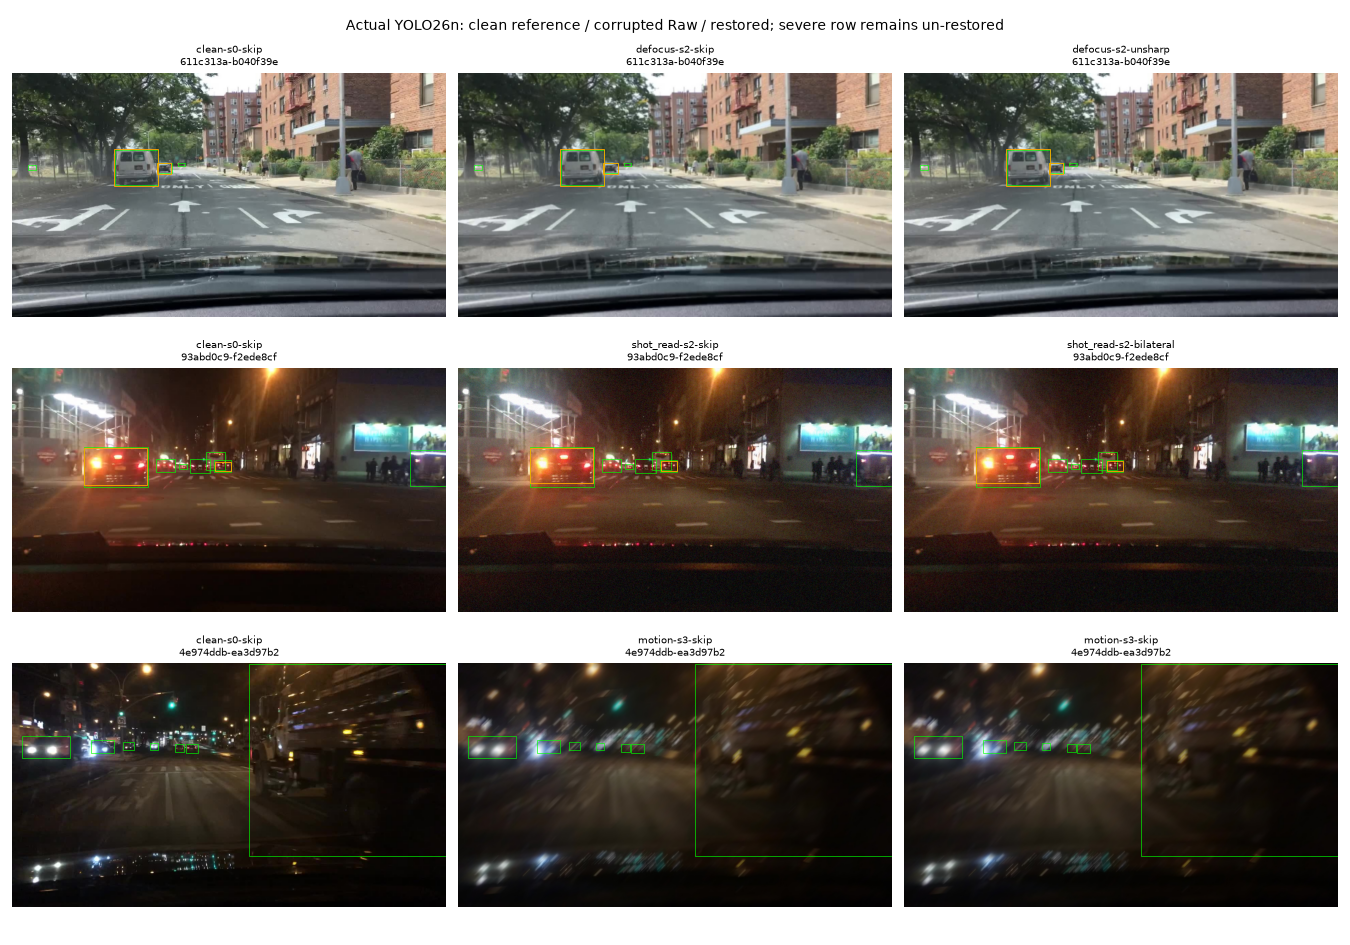

Unchanged original quality/estimator and negative-case evidence:


,family,severity,estimator,images,detection_rate,false_positive_rate,false_negative_rate
0,clean,0,legacy_floor,256,0.000000,0.000000,NaN
1,clean,0,legacy_q95,256,0.000000,0.000000,NaN
2,clean,0,highpass_q95,256,0.050781,0.050781,NaN
3,clean,0,blur_q05,256,0.050781,0.050781,NaN
4,defocus,1,legacy_floor,256,0.000000,0.000000,NaN
5,defocus,1,legacy_q95,256,0.000000,0.000000,NaN
6,defocus,1,highpass_q95,256,0.000000,0.000000,NaN
7,defocus,1,blur_q05,256,0.109375,NaN,0.890625
8,defocus,2,legacy_floor,256,0.000000,0.000000,NaN
9,defocus,2,legacy_q95,256,0.000000,0.000000,NaN


No v3 deployment; eligible group-disjoint confirmation images: 6729


In [5]:
for name in ["severity_grid.png", "detector_examples.png"]:
    display(Image(filename=str(SOURCE / name), width=1100))
print("Unchanged original quality/estimator and negative-case evidence:")
display(pd.read_csv(ROOT / "docs/issue11-v1/estimator_errors.csv").head(12))
screen_groups = {r["group"] for r in pilot["rows"]}
confirmation_rows = [
    r for r in protocol["splits"]["calibration"] if r["group"] not in screen_groups
]
confirmation = {
    "version": "issue11-router-confirmation-gate-v2",
    "status": "not_executed",
    "role": "calibration",
    "protocol_id": protocol["manifest_id"],
    "excluded_screening_pilot_id": pilot["pilot_id"],
    "excluded_group_keys": sorted(screen_groups),
    "eligible_images": len(confirmation_rows),
    "eligible_groups": len({r["group"] for r in confirmation_rows}),
    "eligible_population_id": digest(confirmation_rows),
    "requirements": [
        "freeze pixel-only routing, thresholds and strengths before confirmation outcomes",
        "select representative complete groups disjoint from every screening group",
        "measure clean safety and adverse cases, not only average synthetic gain",
        "report estimator precision/recall and support on known conditions",
        "paired supported-class AP recovery/CI and CPU p50/p95; disclose missing draws",
        "no development/final-test tuning; a changed route requires a new protocol/version",
    ],
    "baseline_label": "Gamma-or-Skip",
    "baseline_policy_id": source_summary["policy_decision"]["retained_policy_id"],
}
confirmation["gate_id"] = digest(confirmation)
freeze(REPORT / "confirmation_gate.json", confirmation)
selected_fields = [
    "family",
    "operator",
    "supported_recovery",
    "supported_recovery_ci_low",
    "supported_recovery_ci_high",
    "supported_clean_loss",
    "restore_p95_ms",
]
decision = {
    "version": "issue11-v3-decision-v2",
    "analysis_id": analysis["analysis_id"],
    "status": "v3_not_deployed",
    "retained_policy_label": "Gamma-or-Skip",
    "retained_policy_id": confirmation["baseline_policy_id"],
    "confirmation_gate_id": confirmation["gate_id"],
    "reason": "Selected-pilot operator evidence does not validate an independent pixel-only router",
    "shortlist_estimand": policy,
    "shortlist": shortlist.loc[shortlist.passes_exploratory_gates, selected_fields].to_dict(
        "records"
    ),
}
decision["decision_id"] = digest(decision)
freeze(REPORT / "v3_decision.json", decision)
print("No v3 deployment; eligible group-disjoint confirmation images:", len(confirmation_rows))

## Bounded #8 specification — metadata only, no final-test execution

Freeze **clean + six synthetic conditions**: shot/read noise, motion and uniform veil,
each at moderate/severe levels. These span distinct mechanisms while bounding cost.
Defocus/exposure and every standalone screened operator remain calibration-only.
For each condition use just **Raw and Gamma-or-Skip**, on identical reserved IDs/GT,
with the pretrained, future Raw-trained and future Gamma-or-Skip-trained models.

That is six natural-clean evaluations plus 36 synthetic evaluations: **42 runs and
408,660 image passes**, rather than 1,109,220 implied by the old full-severity plan.
Prepare at most one condition's input pair at a time and evaluate all three models
before releasing image copies; retain immutable manifests, statistics and result caches.
Natural and synthetic metrics stay separate. Cost estimates extrapolate measured
calibration data and exclude I/O/codec/native AP/plots/startup; they are not wall-time
or worst-case guarantees. Exact trained checkpoint hashes and semantic class mappings
must be frozen at release. Final pixel/geometry/content checks remain outstanding.
There is one final release after model/policy freeze, with identity-safe replay and
no final-result-driven retuning. Expanding the matrix requires a new pre-release version.

In [6]:
spec = final_stress_spec(
    protocol,
    source_study,
    source_matrix,
    confirmation["baseline_policy_id"],
    confirmation["gate_id"],
    support_policy=policy,
)
freeze(REPORT / "final_robustness_spec.json", spec)
display(pd.Series(spec["budget"]))
display(pd.DataFrame(spec["evaluation_matrix"]))
summary = {
    "analysis_id": analysis["analysis_id"],
    "source_study_id": source_study["study_id"],
    "source_commit": "98d7a1f234a6c75e6f06512baef7033060caf8fc",
    "checkpoint_sha256": source_study["checkpoint"],
    "estimand": policy,
    "interval_comparisons": len(intervals),
    "requested_draws_per_comparison": RESAMPLES,
    "valid_draws_total": sum(r["valid_draws"] for r in intervals.values()),
    "invalid_draws_total": sum(r["invalid_draws"] for r in intervals.values()),
    "train_absent_draws_per_comparison": sum(
        d["class_support"][3]["images"] == 0 for d in first["draws"]
    ),
    "clahe_veil": matrix.loc[matrix.experiment == "veil-s2-clahe"].to_dict("records")[0],
    "policy_decision_id": decision["decision_id"],
    "final_spec_id": spec["spec_id"],
    "inference_run": False,
    "training_run": False,
    "final_pixels_accessed": False,
    "point_limitation": "six-class AP is descriptive; CI/gates use the fixed supported target",
    "artifacts": {p.name: file_hash(p) for p in REPORT.iterdir() if p.name != "summary.json"},
}
# Original inference files, historical notebooks, and Issue #6 evidence must not be rewritten.
prior = read_json(RUN_ROOT / "prior_hashes.json")
original_nb = "notebooks/phase2/02b_synthetic_robustness.ipynb"
archived_nb = "notebooks/phase2/evidence/02b_synthetic_robustness_v1.ipynb"
for name, expected in prior.items():
    actual = file_hash(ROOT / (archived_nb if name == original_nb else name))
    if actual != expected:
        raise ValueError("Prior evidence changed: " + name)
write_json(
    REPORT / "prior_evidence_hashes.json",
    {archived_nb if name == original_nb else name: value for name, value in prior.items()},
)
print("PASS: fixed estimand, audited draws, original measurements preserved; no new inference")
print("No v3 deployment or final-test execution. Frozen v2 is Gamma-or-Skip.")
summary["artifacts"] = {
    p.name: file_hash(p) for p in sorted(REPORT.iterdir()) if p.name != "summary.json"
}
write_json(REPORT / "summary.json", summary)

dataset_variants                                                                     14
evaluations                                                                          42
natural_image_passes                                                              58380
synthetic_image_passes                                                           350280
total_image_passes                                                               408660
prepared_image_files                                                             136220
max_simultaneous_datasets                                                             2
disk_policy                           one condition pair at a time; all three models...
image_size_basis                      largest pilot mean; 1.5x headroom; not a worst...
full_retention_image_GiB                                                      132.02748
streaming_image_GiB                                                           18.861069
scratch_GiB                     

,family,severity,treatment,model,images
0,clean,0,Raw,pretrained YOLO26n,9730
1,clean,0,Raw,Raw-trained YOLO26n,9730
2,clean,0,Raw,Gamma-or-Skip-trained YOLO26n,9730
3,clean,0,Gamma-or-Skip,pretrained YOLO26n,9730
4,clean,0,Gamma-or-Skip,Raw-trained YOLO26n,9730
5,clean,0,Gamma-or-Skip,Gamma-or-Skip-trained YOLO26n,9730
6,shot_read,2,Raw,pretrained YOLO26n,9730
7,shot_read,2,Raw,Raw-trained YOLO26n,9730
8,shot_read,2,Raw,Gamma-or-Skip-trained YOLO26n,9730
9,shot_read,2,Gamma-or-Skip,pretrained YOLO26n,9730


PASS: fixed estimand, audited draws, original measurements preserved; no new inference
No v3 deployment or final-test execution. Frozen v2 is Gamma-or-Skip.
